In [1]:

# Import libraries and check GPU

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

import os
import shutil
import json

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)

gpu = tf.config.list_physical_devices('GPU')
print("GPU Available:", gpu)


TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
#installing kaggel hub for data set

!pip install -q kagglehub

In [3]:
#now Downloading PlantVillage dataset
import kagglehub

path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/plantdisease


In [4]:
#Find the dataset folders
for root, dirs, files in os.walk(path):
    if dirs:
        print("\nFolder:", root)
        print("Subfolders:", dirs[:10])
        break


Folder: /kaggle/input/plantdisease
Subfolders: ['PlantVillage', 'plantvillage']


In [5]:
selected_classes = [
    # Pepper
    "Pepper__bell___healthy",
    "Pepper__bell___Bacterial_spot",

    # Potato
    "Potato___healthy",
    "Potato___Early_blight",

    # Tomato
    "Tomato_healthy",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "Tomato__Tomato_mosaic_virus"]

available_folders = {}

for root, dirs, files in os.walk(path):
    for folder in dirs:
        available_folders[folder] = os.path.join(root, folder)

print("Checking selected classes:\n")

for cls in selected_classes:
    if cls in available_folders:
        print("FOUND:", cls)
    else:
        print("NOT FOUND:", cls)

Checking selected classes:

FOUND: Pepper__bell___healthy
FOUND: Pepper__bell___Bacterial_spot
FOUND: Potato___healthy
FOUND: Potato___Early_blight
FOUND: Tomato_healthy
FOUND: Tomato_Early_blight
FOUND: Tomato_Late_blight
FOUND: Tomato_Leaf_Mold
FOUND: Tomato__Tomato_YellowLeaf__Curl_Virus
FOUND: Tomato__Tomato_mosaic_virus


In [6]:
# Verify classes and split the dataset
# Create training, validation and testing folders
import os
import shutil

from sklearn.model_selection import train_test_split

# Check selected classes
available_folders = {}

for root, dirs, files in os.walk(path):
    for folder in dirs:
        available_folders[folder] = os.path.join(root, folder)

missing = [
    cls for cls in selected_classes
    if cls not in available_folders
]

if missing:
    print("Missing classes:")
    for cls in missing:
        print(cls)

else:
    print("All 10 classes found!")

    dataset_output = "/content/PlantGuard_Dataset"

    # Remove previous output if rerunning
    if os.path.exists(dataset_output):
        shutil.rmtree(dataset_output)

    for split in ["train", "validation", "test"]:
        os.makedirs(
            os.path.join(dataset_output, split),
            exist_ok=True
        )

    image_extensions = (".jpg", ".jpeg", ".png")

    for cls in selected_classes:

        source_folder = available_folders[cls]

        images = [
            f for f in os.listdir(source_folder)
            if f.lower().endswith(image_extensions)
        ]

        train_images, temp_images = train_test_split(
            images,
            test_size=0.30,
            random_state=42
        )

        val_images, test_images = train_test_split(
            temp_images,
            test_size=0.50,
            random_state=42
        )

        image_splits = {
            "train": train_images,
            "validation": val_images,
            "test": test_images
        }

        for split, files in image_splits.items():

            destination = os.path.join(
                dataset_output, split, cls
            )

            os.makedirs(destination, exist_ok=True)

            for file in files:
                shutil.copy2(
                    os.path.join(source_folder, file),
                    os.path.join(destination, file)
                )

        print(
            cls,
            "| Train:", len(train_images),
            "| Validation:", len(val_images),
            "| Test:", len(test_images)
        )

    print("\nDataset preparation completed!")

All 10 classes found!
Pepper__bell___healthy | Train: 1034 | Validation: 222 | Test: 222
Pepper__bell___Bacterial_spot | Train: 697 | Validation: 150 | Test: 150
Potato___healthy | Train: 106 | Validation: 23 | Test: 23
Potato___Early_blight | Train: 700 | Validation: 150 | Test: 150
Tomato_healthy | Train: 1113 | Validation: 239 | Test: 239
Tomato_Early_blight | Train: 700 | Validation: 150 | Test: 150
Tomato_Late_blight | Train: 1336 | Validation: 286 | Test: 287
Tomato_Leaf_Mold | Train: 666 | Validation: 143 | Test: 143
Tomato__Tomato_YellowLeaf__Curl_Virus | Train: 2245 | Validation: 481 | Test: 482
Tomato__Tomato_mosaic_virus | Train: 261 | Validation: 56 | Test: 56

Dataset preparation completed!


In [7]:
# Check dataset counts

for split in ["train", "validation", "test"]:

    split_path = os.path.join(dataset_output, split)

    total_images = sum(
        len(files)
        for _, _, files in os.walk(split_path)
    )

    print(split.upper(), ":", total_images, "images")

TRAIN : 8858 images
VALIDATION : 1900 images
TEST : 1902 images


In [8]:
import tensorflow as tf
import os

IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_output, "train"),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

# Load validation dataset
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_output, "validation"),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# Load testing dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_output, "test"),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)

print("\nClass Names:", class_names)
print("Number of Classes:", NUM_CLASSES)
print("Datasets loaded successfully!")

Found 8858 files belonging to 10 classes.
Found 1900 files belonging to 10 classes.
Found 1902 files belonging to 10 classes.

Class Names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of Classes: 10
Datasets loaded successfully!


In [9]:
#Normalize the images
# Normalize pixel values from 0 to 1
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

# Optimize dataset loading
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Image preprocessing completed successfully!")

Image preprocessing completed successfully!


In [10]:
#Verify image preprocessing
for images, labels in train_dataset.take(1):

    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image shape: (32, 128, 128, 3)
Label shape: (32, 10)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


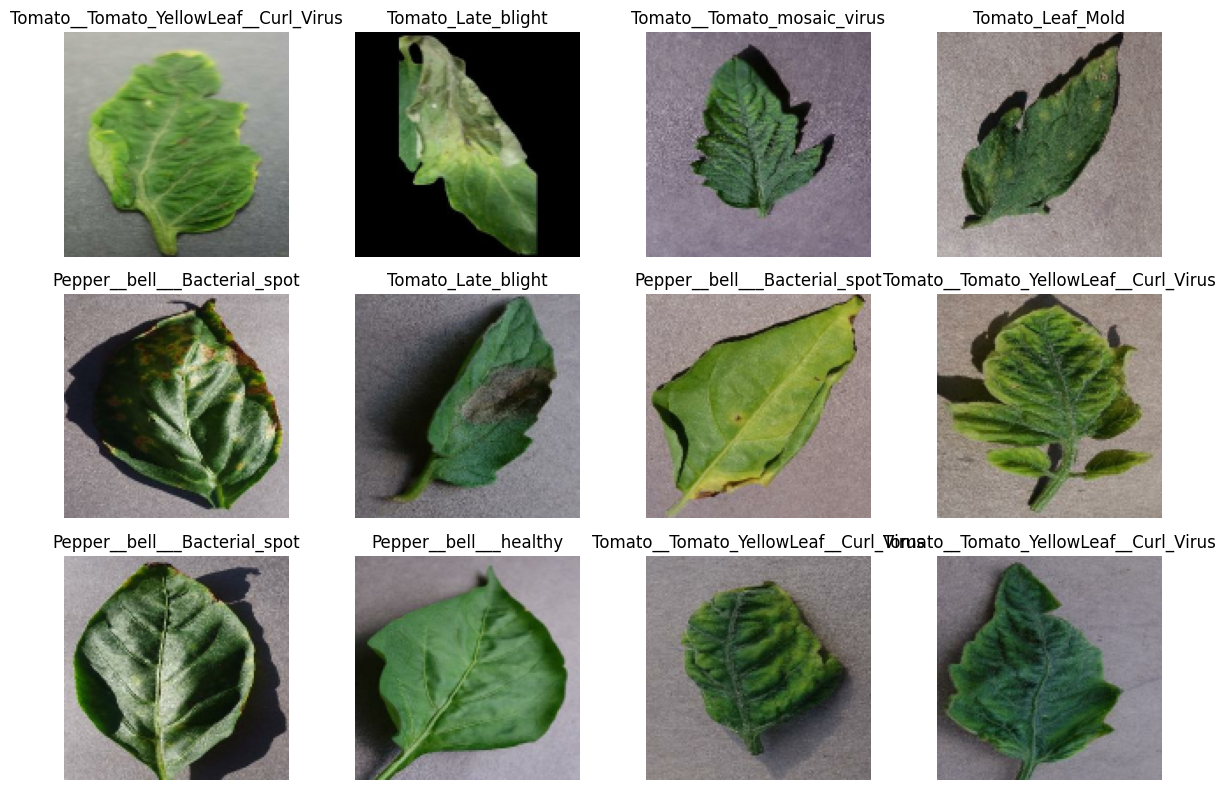

In [11]:
#Display sample images
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy())

        label_index = np.argmax(labels[i].numpy())

        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
#Create CNN architecture
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(
        128, (3, 3),
        activation='relu',
        name="last_conv"
    ),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#Compile the CNN model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [14]:
#Calculate class weights
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Count training images in each class
class_counts = []

for cls in class_names:
    folder = os.path.join(dataset_output, "train", cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    class_counts.append(count)

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=np.concatenate([
        np.full(count, i)
        for i, count in enumerate(class_counts)
    ])
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(weights)
}

print("Class names:", class_names)
print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Class counts: [697, 1034, 700, 106, 700, 1336, 666, 2245, 261, 1113]
Class weights: {0: 1.2708751793400288, 1: 0.8566731141199226, 2: 1.2654285714285713, 3: 8.356603773584906, 4: 1.2654285714285713, 5: 0.6630239520958083, 6: 1.33003003003003, 7: 0.39456570155902004, 8: 3.3938697318007662, 9: 0.7958670260557053}


In [15]:
#Train the CNN model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Training callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

checkpoint = ModelCheckpoint(
    "best_plantguard_model.keras",
    monitor="val_accuracy",
    save_best_only=True
)

# Train model
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

print("CNN training completed!")

Epoch 1/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.4121 - loss: 1.7055 - val_accuracy: 0.6616 - val_loss: 1.0043 - learning_rate: 0.0010
Epoch 2/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.6486 - loss: 1.0513 - val_accuracy: 0.7384 - val_loss: 0.7103 - learning_rate: 0.0010
Epoch 3/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.7157 - loss: 0.8520 - val_accuracy: 0.8368 - val_loss: 0.4518 - learning_rate: 0.0010
Epoch 4/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.7354 - loss: 0.7885 - val_accuracy: 0.8253 - val_loss: 0.5277 - learning_rate: 0.0010
Epoch 5/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.7821 - loss: 0.6417 - val_accuracy: 0.8632 - val_loss: 0.3795 - learning_rate: 0.0010
Epoch 6/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.7997 - loss: 0.6108 - val_accuracy: 0.8642 - val_loss: 0.3772 - learning_rate: 0.0010
Epoch 7/20
277/277 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.8119 - lo

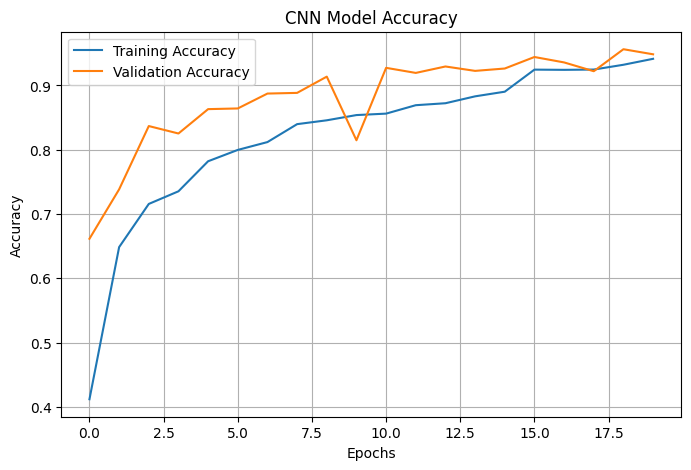

In [16]:
#Plot training accuracy and loss
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

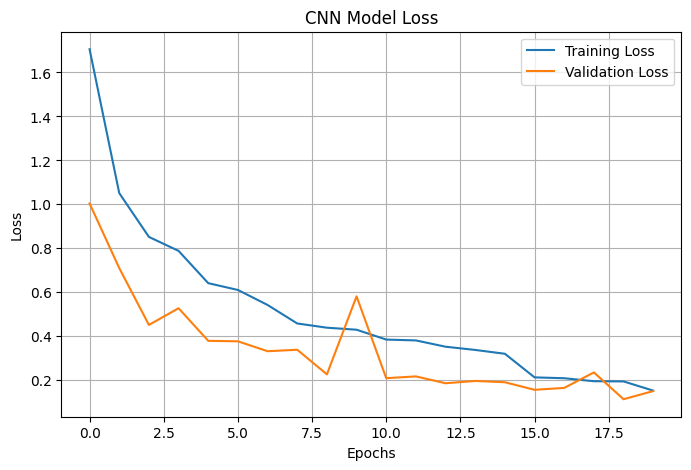

In [17]:
#Loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
#Load the best saved model
model = tf.keras.models.load_model(
    "best_plantguard_model.keras"
)

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [19]:
#Evaluate the test dataset
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9527 - loss: 0.1268
Test Loss: 0.1268327534198761
Test Accuracy: 95.26813626289368 %


In [20]:
#Generate predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

print("Predictions completed!")

Predictions completed!


In [21]:
#Classification report
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                       precision    recall  f1-score   support

        Pepper__bell___Bacterial_spot       0.95      0.94      0.95       150
               Pepper__bell___healthy       0.96      1.00      0.98       222
                Potato___Early_blight       0.89      0.98      0.93       150
                     Potato___healthy       0.92      0.96      0.94        23
                  Tomato_Early_blight       0.80      0.92      0.86       150
                   Tomato_Late_blight       0.97      0.84      0.90       287
                     Tomato_Leaf_Mold       0.98      0.91      0.94       143
Tomato__Tomato_YellowLeaf__Curl_Virus       1.00      0.99      0.99       482
          Tomato__Tomato_mosaic_virus       0.93      1.00      0.97        56
                       Tomato_healthy       0.99      1.00      0.99       239

                             accuracy                           0.95      1902
                            macro avg       0.94  

<Figure size 1200x1000 with 0 Axes>

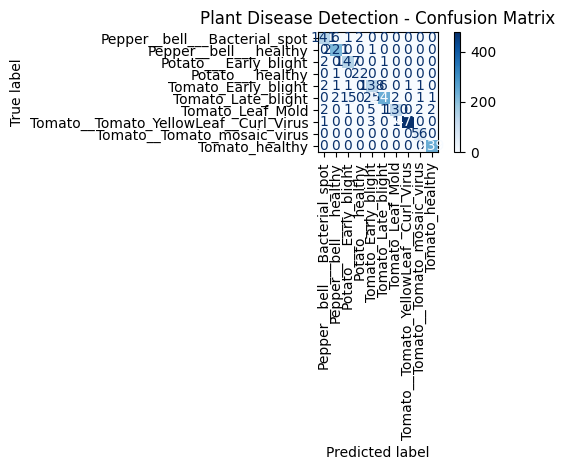

In [22]:
#Confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d"
)

plt.title("Plant Disease Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
# Import Grad-CAM libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [24]:
# Initialize CNN model for Grad-CAM
dummy_input = tf.zeros((1, 128, 128, 3))
_ = model(dummy_input)

print("CNN model initialized successfully!")

CNN model initialized successfully!


In [25]:
#Create corrected Grad-CAM model
inputs = tf.keras.Input(shape=(128, 128, 3))

x = inputs

for layer in model.layers:
    x = layer(x)

functional_model = tf.keras.Model(
    inputs=inputs,
    outputs=x
)

grad_model = tf.keras.Model(
    inputs=functional_model.inputs,
    outputs=[
        functional_model.get_layer("last_conv").output,
        functional_model.output
    ]
)

print("Grad-CAM model created successfully!")

Grad-CAM model created successfully!


In [26]:
#Grad-CAM function

def generate_gradcam(image, grad_model):

    image = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image, training=False
        )

        predicted_class = tf.argmax(predictions[0])
        loss = predictions[:, predicted_class]

    gradients = tape.gradient(loss, conv_outputs)

    if gradients is None:
        raise ValueError("Gradients are missing!")

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        predictions[0].numpy()
    )

print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


In [27]:
# Save the trained CNN model
model.save("plant_disease_model.keras")

print("Plant disease model saved successfully!")

Plant disease model saved successfully!


In [28]:
#Save class names
import json

# Save all 10 class names
with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")
print(class_names)

Class names saved successfully!
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [29]:
#Check saved files
import os

print("Saved project files:")

for file in ["plant_disease_model.keras", "class_names.json"]:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("NOT FOUND:", file)

Saved project files:
FOUND: plant_disease_model.keras
FOUND: class_names.json


In [30]:
#Download files to your computer
from google.colab import files

files.download("plant_disease_model.keras")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>